# 用发电量、历史价格与时间特征预测电价

目标：数据集中的 `price actual`。预测时刻 t 的价格，只使用 t−1 及更早的实测信息，以及提前已知的 calendar_t。
用户已允许历史价格。本 notebook 比较发电量、历史价格和它们的组合，检查发电量的增量价值。

原始 CSV、try.ipynb 和上一份燃气预测 notebook 均不修改。价格单位按该数据集公开说明采用 EUR/MWh；CSV 本身没有单位元数据。
`price actual` 的具体结算产品和发布时间未核实，因此这里是滚动一步预测的统计练习，不称它为实时/平衡市场价格，也不推断交易收益。
`price day ahead`、负荷、天气和未来实测发电量均不进入主实验，避免混淆本次要研究的信息来源。

先做三个开发时间窗口，再冻结每类方案和树轮数；最后15%仅用于最终报告，不用于early stopping或选模型。全部代码可按顺序运行。


## 阅读路线：把特征与训练流程分开

本次重构保留全部特征、三个时间窗口、八组实验和选型规则，只整理代码结构。
特征构造到 `make_feature_sets` 为止；后面的训练流程按下面的顺序阅读：

**准备 X/y → 按时间切分 → 在 train 拟合、valid early stopping → 预测并评分 → 冻结方案 → 重训 → test 评价。**

| 代码 | 只负责什么 |
|---|---|
| `split_xy` | 根据时间位置取得训练和验证的 X/y |
| `fit_with_validation` | 拟合 Ridge、XGB 或 Ridge + 残差 XGB |
| `predict_model` | 用已拟合的模型预测，不更新模型 |
| `evaluate` | 用真实值和预测值计算指标，不训练模型 |
| 最终重训 cell | 用固定树轮数重新 fit，只传训练数据 |

三个时间窗口和八组实验只是重复调用这几个步骤。迁移到其他任务时，可以先运行一个时间窗口、一个模型。
`sklearn.Pipeline` 在这里专门封装 Ridge 的 **填补 → 标准化 → 回归**；整个机器学习流程还包含它之外的切分、验证和评价。


结果记录（重构后重新运行）

以下记录本次固定配置的结果；修改特征或模型后，以重新执行的输出为准。三段开发窗口选择了 **历史价格＋时间特征的Ridge＋XGB**，然后冻结方案，在最后15%作最终评价。

| 最终测试方案 | RMSE（EUR/MWh） | MAE（EUR/MWh） | R² |
|---|---:|---:|---:|
| 上一小时价格基线 | 2.8775 | 1.9722 | 0.8674 |
| 发电量历史＋时间，XGB | 12.9755 | 10.9196 | −1.6955 |
| 历史价格＋时间，Ridge＋XGB | 1.7048 | 1.2304 | 0.9535 |
| 发电量＋历史价格＋时间，Ridge＋XGB | 1.7049 | 1.2287 | 0.9535 |

被开发阶段选中的模型相对lag1基线降低RMSE约40.8%。加入发电量后，主验证与最终测试均没有明显的额外改善。
因此不能据此说“换成电价任务就更好”：在同一主验证时段，上轮燃气模型相对各自lag1基线改善43.1%，本轮电价改善38.3%。这些比较只适用于当前信息集合、一步跨度和已尝试模型。

学习重点是：短期自回归状态很重要；发电量与价格的同期相关不保证跨时间稳定的预测增量。发电量模型的负测试R²也提示需要检查年份间变化和遗漏的信息，不能仅看训练拟合。


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import xgboost
import sklearn
from xgboost import XGBRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})
SOURCE = Path('energy_dataset.csv')
if not SOURCE.exists():
    SOURCE = Path('/Users/jiongwu/Documents/Python_Leetcode/Squarepoint/data-anlysis/energy_dataset.csv')
if not SOURCE.exists():
    raise FileNotFoundError('请把CSV放在当前目录，或修改SOURCE。')
data = pd.read_csv(SOURCE)
data.index = pd.DatetimeIndex(pd.to_datetime(data.pop('time'), utc=True))
data = data.sort_index()
assert data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq='h'))
TARGET = 'price actual'
PUMP = 'generation hydro pumped storage consumption'
y = data[TARGET]
n = len(data)
train_end, validation_end = int(n * .70), int(n * .85)
MIN_HISTORY = 169
local = data.index.tz_convert('Europe/Madrid')
print('Versions:', {m.__name__: m.__version__ for m in [pd, np, xgboost, sklearn]})
print('Rows:', n, 'Target:', TARGET)
print('Training:', data.index[0], 'through', data.index[train_end-1])
print('Validation:', data.index[train_end], 'through', data.index[validation_end-1])
print('Reserved test:', data.index[validation_end], 'through', data.index[-1])


Versions: {'pandas': '2.3.3', 'numpy': '1.26.4', 'xgboost': '3.2.0', 'sklearn': '1.7.2'}
Rows: 35064 Target: price actual
Training: 2014-12-31 23:00:00+00:00 through 2017-10-19 14:00:00+00:00
Validation: 2017-10-19 15:00:00+00:00 through 2018-05-26 18:00:00+00:00
Reserved test: 2018-05-26 19:00:00+00:00 through 2018-12-31 22:00:00+00:00


## 数据检查与训练期 EDA

不给缺失价格补均值，不把真实零值自动当缺失。每个fold仅依据其训练段排除全空或常数发电列。
注意：`hydro pumped storage consumption` 是抽水蓄能耗电，虽以generation开头，也不能计入发电总量或可再生发电量。
保留它作为单独的历史储能运行特征。UTC用于排序和shift，Madrid当地时间用于日历；DST附近lag24不是严格的昨日同一当地钟点。


In [2]:
train = data.iloc[:train_end]
generation_columns = list(data.filter(regex='^generation ').columns)
audit = pd.DataFrame({'missing': train[generation_columns].isna().sum(),
                      'unique': train[generation_columns].nunique(),
                      'mean': train[generation_columns].mean()})
print('Training-only generation audit:\n', audit.round(2).to_string())
print('\nTraining price summary:\n', train[TARGET].describe().round(3).to_string())
print('\nPrice missing values by split:', {
    'train': int(y.iloc[:train_end].isna().sum()),
    'validation': int(y.iloc[train_end:validation_end].isna().sum())})
lag_correlations = pd.Series({lag: train[TARGET].autocorr(lag) for lag in [1, 2, 3, 24, 48, 168]})
print('\nTraining price autocorrelations:\n', lag_correlations.round(3).to_string())


Training-only generation audit:
                                              missing  unique     mean
generation biomass                                18     422   402.68
generation fossil brown coal/lignite              17     933   472.28
generation fossil coal-derived gas                17       1     0.00
generation fossil gas                             17    7116  5438.81
generation fossil hard coal                       17    7062  4421.45
generation fossil oil                             18     314   304.32
generation fossil oil shale                       17       1     0.00
generation fossil peat                            17       1     0.00
generation geothermal                             17       1     0.00
generation hydro pumped storage aggregated     24544       0      NaN
generation hydro pumped storage consumption       18    3046   503.07
generation hydro run-of-river and poundage        18    1625   902.89
generation hydro water reservoir                  17    6

/Users/jiongwu/miniforge3/envs/py311-arm64/lib/python3.11/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/jiongwu/miniforge3/envs/py311-arm64/lib/python3.11/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


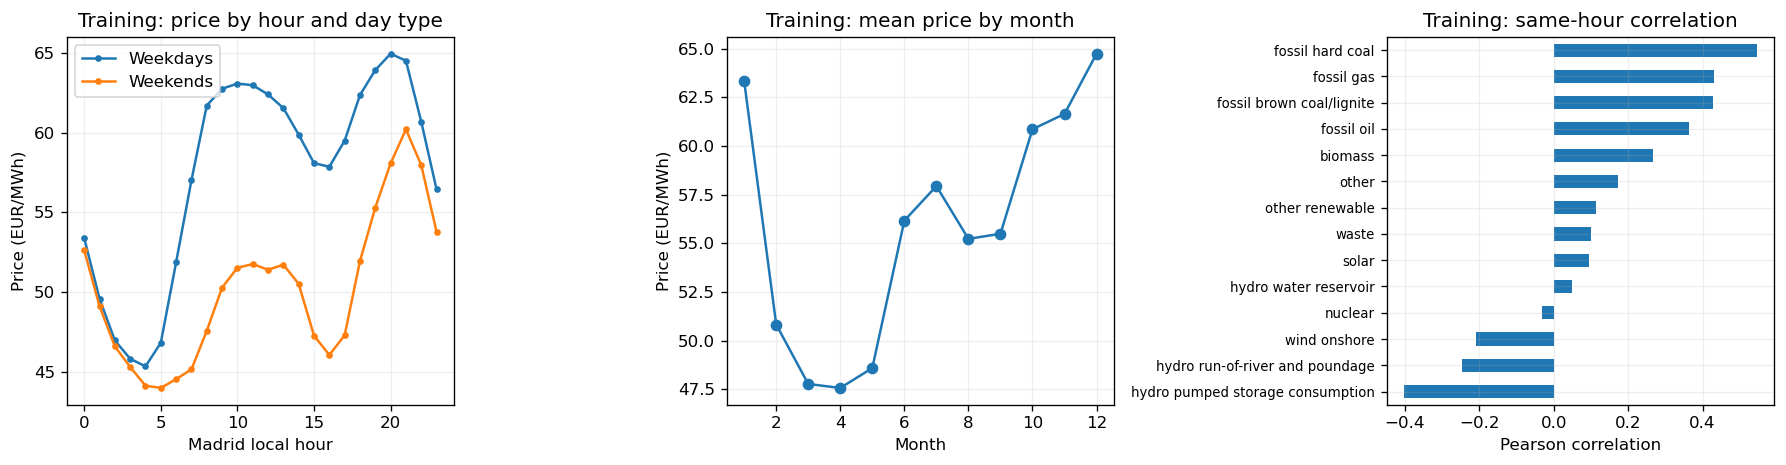

In [3]:
ix = local[:train_end]
price_train = train[TARGET]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for weekend, label in [(False, 'Weekdays'), (True, 'Weekends')]:
    mask = (ix.dayofweek >= 5) == weekend
    price_train.loc[mask].groupby(ix[mask].hour).mean().plot(ax=axes[0], marker='.', label=label)
axes[0].set(title='Training: price by hour and day type', xlabel='Madrid local hour', ylabel='Price (EUR/MWh)')
axes[0].legend()
price_train.groupby(ix.month).mean().plot(ax=axes[1], marker='o')
axes[1].set(title='Training: mean price by month', xlabel='Month', ylabel='Price (EUR/MWh)')
corr = train[generation_columns].corrwith(price_train).dropna().sort_values()
corr.plot(kind='barh', ax=axes[2])
axes[2].set(title='Training: same-hour correlation', xlabel='Pearson correlation')
axes[2].set_yticklabels([name.removeprefix('generation ') for name in corr.index], fontsize=8)
plt.tight_layout()
plt.show()


## 从 EDA 到特征假设

- 时间：目标时刻hour、weekday、month、年内位置、weekend；hour一至三阶Fourier和weekend交互，另有周/年周期编码。
- 发电量：各列lag1/2/3/24/168，过去3/24小时mean/std，最近ramp和24小时变化。只用历史实测。
- 发电结构：选定发电源之和、化石燃料发电、wind+solar、水电及其占比与变化；分母不包含抽蓄耗电。
- 历史价格：lag1/2/3/6/12/23/24/25/48/72/167/168/169，过去3/24/168小时mean/std，以及变化量。
- 太阳能季节背景：训练段month×hour典型水平，以及上一小时实际值相对典型值的偏差。

同期相关只用于提出假设，预测特征仍使用shift；发电与价格共同受需求、燃料成本、调度等影响，相关不等于因果。
不强加“风光越多价格一定越低”的单调约束。树模型不要求正态化；price不能盲目log，因为其他时期或市场可能出现零/负价。


In [4]:
def calendar_features(index):
    loc = index.tz_convert('Europe/Madrid')
    result = pd.DataFrame({'hour': loc.hour, 'weekday': loc.dayofweek,
                           'month': loc.month, 'dayofyear': loc.dayofyear,
                           'weekend': (loc.dayofweek >= 5).astype(int)}, index=index)
    for name, values, period in [('hour', loc.hour, 24), ('weekday', loc.dayofweek, 7),
                                  ('annual', loc.dayofyear - 1, 365.25)]:
        for trig, func in [('sin', np.sin), ('cos', np.cos)]:
            result[f'{name}_{trig}'] = func(2*np.pi*values/period)
    for k in [2, 3]:
        result[f'hour_sin_{k}'] = np.sin(2*np.pi*k*loc.hour/24)
        result[f'hour_cos_{k}'] = np.cos(2*np.pi*k*loc.hour/24)
    for k in [1, 2, 3]:
        for trig, func in [('sin', np.sin), ('cos', np.cos)]:
            result[f'weekend_hour_{trig}_{k}'] = (loc.dayofweek >= 5)*func(2*np.pi*k*loc.hour/24)
    return result

def history_features(frame, lags, windows):
    columns = {}
    for name in frame:
        s = frame[name]
        for lag in lags:
            columns[f'{name}_lag{lag}'] = s.shift(lag)
        past = s.shift(1)
        for window in windows:
            r = past.rolling(window, min_periods=window)
            columns[f'{name}_mean{window}'] = r.mean()
            columns[f'{name}_std{window}'] = r.std()
        columns[f'{name}_ramp1'] = past - s.shift(2)
        columns[f'{name}_change24'] = past - s.shift(25)
    return pd.DataFrame(columns, index=frame.index)

def make_feature_sets(frame, fit_end):
    # Column eligibility is decided from THIS fold's training interval only.
    candidates = list(frame.filter(regex='^generation ').columns)
    active = [c for c in candidates if frame[c].iloc[:fit_end].nunique(dropna=True) > 1]
    actual_generation = [c for c in active if c != PUMP]
    generation = frame[active].copy()
    generation.columns = generation.columns.str.removeprefix('generation ')
    cal = calendar_features(frame.index)
    gen_lag1 = generation.shift(1).add_suffix('_lag1')
    gen_hist = history_features(generation, [1, 2, 3, 24, 168], [3, 24])

    group_columns = {
        'selected_generation_total': actual_generation,
        'fossil_generation': [c for c in actual_generation if 'fossil ' in c],
        'wind_solar_generation': [c for c in actual_generation if 'wind ' in c or c == 'generation solar'],
        'hydro_generation': [c for c in actual_generation if 'hydro ' in c],
    }
    assert PUMP not in group_columns['selected_generation_total']
    groups = pd.DataFrame(index=frame.index)
    for name, cols in group_columns.items():
        groups[name] = frame[cols].sum(axis=1, min_count=len(cols)) if cols else np.nan
    mix = groups.shift(1).add_suffix('_lag1')
    denominator = groups['selected_generation_total'].shift(1).replace(0, np.nan)
    for name in ['fossil_generation', 'wind_solar_generation', 'hydro_generation']:
        mix[f'{name}_share_lag1'] = groups[name].shift(1)/denominator
        mix[f'{name}_ramp1'] = groups[name].shift(1)-groups[name].shift(2)

    loc = frame.index.tz_convert('Europe/Madrid')
    solar_train = frame['generation solar'].iloc[:fit_end]
    table = solar_train.groupby([loc[:fit_end].month, loc[:fit_end].hour]).mean()
    def profile_at(index):
        keys = pd.MultiIndex.from_arrays([index.month, index.hour])
        return pd.Series(table.reindex(keys).to_numpy(), index=frame.index)
    profile = pd.DataFrame(index=frame.index)
    profile['solar_typical_at_target_hour'] = profile_at(loc)
    previous_loc = (frame.index-pd.Timedelta(hours=1)).tz_convert('Europe/Madrid')
    profile['solar_anomaly_lag1'] = frame['generation solar'].shift(1)-profile_at(previous_loc)

    p = frame[[TARGET]].rename(columns={TARGET:'price'})
    price_hist = history_features(p, [1, 2, 3, 6, 12, 23, 24, 25, 48, 72, 167, 168, 169], [3, 24, 168])
    price_hist['price_deviation24'] = p['price'].shift(1)-p['price'].shift(1).rolling(24).mean()
    return {
        'calendar': cal,
        'generation_simple': pd.concat([gen_lag1, cal], axis=1),
        'generation_engineered': pd.concat([gen_hist, mix, profile, cal], axis=1),
        'price_history': pd.concat([price_hist, cal], axis=1),
        'combined': pd.concat([gen_hist, mix, profile, price_hist, cal], axis=1),
    }


## 1. 集中放置实验配置

五套 features 全部保留。每行配置只回答三个问题：用哪套特征、用什么模型、属于哪类信息集合。
`xgb` 直接学习价格；`ridge` 只用线性模型；`ridge+xgb` 先拟合 Ridge，再用 XGB 学习残差。
最终预测为 `Ridge预测 + XGB残差预测`，不是把两个价格预测简单平均。

XGB 保留 NaN，不需要标准化。Ridge 的填补器和标准化器在每次 `.fit(X_train, y_train)` 时只学习当前训练数据。


In [5]:
XGB_PARAMS = dict(
    objective='reg:squarederror', tree_method='hist', n_estimators=1800,
    learning_rate=.04, max_depth=4, min_child_weight=10,
    subsample=.8, colsample_bytree=.8, reg_lambda=10., reg_alpha=.1,
    eval_metric='rmse', random_state=42, n_jobs=4,
)
EARLY_STOPPING_ROUNDS = 80
RIDGE_ALPHA = 100.

experiments = pd.DataFrame([
    # name                      feature_set               model_type   family
    ('calendar_xgb',            'calendar',               'xgb',       'calendar'),
    ('generation_simple_xgb',   'generation_simple',      'xgb',       'generation'),
    ('generation_engineered_xgb', 'generation_engineered', 'xgb',      'generation'),
    ('price_history_xgb',       'price_history',          'xgb',       'price_history'),
    ('price_history_hybrid',    'price_history',          'ridge+xgb', 'price_history'),
    ('combined_xgb',            'combined',               'xgb',       'combined'),
    ('combined_ridge',          'combined',               'ridge',     'combined'),
    ('combined_hybrid',         'combined',               'ridge+xgb', 'combined'),
], columns=['name', 'feature_set', 'model_type', 'family']).set_index('name')

# (名称, 训练结束位置, 验证结束位置)，右端点不包含在区间中。
FOLDS = [
    ('early_50', int(n * .50), int(n * .60)),
    ('early_60', int(n * .60), train_end),
    ('main', train_end, validation_end),
]
display(experiments)


,feature_set,model_type,family
name,,,
calendar_xgb,calendar,xgb,calendar
generation_simple_xgb,generation_simple,xgb,generation
generation_engineered_xgb,generation_engineered,xgb,generation
price_history_xgb,price_history,xgb,price_history
price_history_hybrid,price_history,ridge+xgb,price_history
combined_xgb,combined,xgb,combined
combined_ridge,combined,ridge,combined
combined_hybrid,combined,ridge+xgb,combined


## 2. 切分 X/y，定义统一指标

X 的每行对应目标时刻 t；这一行的实测特征已经在上游 shift 到 t−1 或更早，因此 **这里不再 shift y**。
所有模型从第 169 行开始训练。缺失标签只从训练/评分样本中排除，不给 y 填均值；也不因为 X 中有 NaN 就整行删除。
验证集保留边界前已有的历史，不重新丢弃 169 小时。

先看 RMSE、MAE 和相对 lag1 基线的 `skill = 1 − 模型RMSE / 基线RMSE`。
保留 R²、NRMSE 和 MASE1 供进一步学习：NRMSE 使用评价段标准差（ddof=0），等于 `sqrt(1−R²)`；
MASE1 使用训练段原始小时序列的一阶差分绝对值均值作分母，计算前不能先删除缺失小时。


In [6]:
def split_xy(X, target, fit_end, eval_end, min_history):
    """按位置切分，用相同时间索引对齐 X 和 y；不做任何拟合。"""
    y_train = target.iloc[min_history:fit_end].dropna()
    y_valid = target.iloc[fit_end:eval_end].dropna()
    X_train = X.loc[y_train.index]
    X_valid = X.loc[y_valid.index]
    return X_train, X_valid, y_train, y_valid


def evaluate(actual, prediction, naive_prediction, training_y):
    """只评分；training_y 保留完整训练时间索引，用于 MASE 分母。"""
    rmse = float(np.sqrt(mean_squared_error(actual, prediction)))
    mae = float(mean_absolute_error(actual, prediction))
    naive_rmse = float(np.sqrt(mean_squared_error(actual, naive_prediction)))
    return dict(
        rmse=rmse,
        mae=mae,
        r2=float(r2_score(actual, prediction)),
        nrmse=rmse / float(actual.std(ddof=0)),
        skill=1 - rmse / naive_rmse,
        mase1=mae / float(training_y.diff().abs().mean()),
    )


def evaluate_baselines(target, fit_end, eval_end):
    """在相同评价时点，比较上一小时、前24小时、前168小时价格。"""
    actual = target.iloc[fit_end:eval_end].dropna()
    naive1 = target.ffill().shift(1).loc[actual.index]
    rows = []
    for lag in [1, 24, 168]:
        prediction = target.ffill().shift(lag).loc[actual.index]
        scores = evaluate(actual, prediction, naive1, target.iloc[:fit_end])
        rows.append(dict(name=f'naive_lag{lag}', family='baseline', **scores))
    return rows


## 3. 训练与预测分开写

下面的训练函数只接收已经切好的四个对象，不读取全局 y，也不切分数据或评分。
先读 `model_type='xgb'` 的路径：线性预测为 0，XGB 直接拟合 y。
再读 `ridge+xgb` 的路径：① fit Ridge；② 用 `y − Ridge预测` 得到训练与验证残差；③ fit XGB。
验证残差只用于 early stopping，不加入训练样本。

`predict_model` 把两部分预测相加；只有其中一个模型时，另一部分为 0。
XGB 在这里的 sklearn 接口预测默认使用 early stopping 选出的最佳迭代。


In [7]:
def fit_with_validation(X_train, y_train, X_valid, y_valid,
                        model_type, xgb_params, patience, ridge_alpha):
    """开发阶段拟合：只有 valid 用于 early stopping。"""
    if model_type not in ['xgb', 'ridge', 'ridge+xgb']:
        raise ValueError(f'Unknown model_type: {model_type}')
    linear, tree = None, None
    linear_train = np.zeros(len(y_train))
    linear_valid = np.zeros(len(y_valid))

    # 1. 可选线性部分：预处理与 Ridge 一起 fit。
    if model_type in ['ridge', 'ridge+xgb']:
        linear = make_pipeline(
            SimpleImputer(strategy='median', add_indicator=True),
            StandardScaler(), Ridge(alpha=ridge_alpha),
        )
        linear.fit(X_train, y_train)
        linear_train = linear.predict(X_train)
        linear_valid = linear.predict(X_valid)

    # 2. 可选树部分：没有 Ridge 时，残差就是原始 y。
    if model_type in ['xgb', 'ridge+xgb']:
        tree = XGBRegressor(**xgb_params, early_stopping_rounds=patience)
        tree.fit(
            X_train, y_train - linear_train,
            eval_set=[(X_valid, y_valid - linear_valid)],
            verbose=False,
        )
    return {'linear': linear, 'tree': tree, 'columns': list(X_train.columns)}


def predict_model(model, X):
    """预测不需要真实 y，也不会重新 fit 预处理器。"""
    prediction = np.zeros(len(X))
    if model['linear'] is not None:
        prediction += model['linear'].predict(X)
    if model['tree'] is not None:
        prediction += model['tree'].predict(X)
    return pd.Series(prediction, index=X.index)


## 4. 在开发窗口重复同一个小流程

先看内层的五步：**取 X → split → fit → predict → evaluate**。外层 fold 仅重复不同的时间窗口。
每个 fold 都用自己的训练截止点重建特征，重新估计活跃发电列、solar profile、imputer 和 scaler。
三段开发窗口及参数与重构前相同；验证分数参与 early stopping 和选型，因此不作为最终测试成绩。

只练习一个模型时，可以让 `FOLDS` 仅保留 `main` 这一行，并把 `experiments` 缩成一行；
后面冻结方案的 cell 也支持这两种改动，无需改训练函数。


In [8]:
development_rows = []
for fold, fit_end, eval_end in FOLDS:
    feature_sets = make_feature_sets(data, fit_end)
    baseline_scores = evaluate_baselines(y, fit_end, eval_end)
    development_rows.extend(dict(fold=fold, **row) for row in baseline_scores)

    for name, spec in experiments.iterrows():
        # 1. 取 X；2. 切分。
        X = feature_sets[spec.feature_set]
        X_train, X_valid, y_train, y_valid = split_xy(
            X, y, fit_end, eval_end, MIN_HISTORY,
        )

        # 3. 训练。参数、输入和验证集都明确传入。
        model = fit_with_validation(
            X_train, y_train, X_valid, y_valid,
            spec.model_type, XGB_PARAMS, EARLY_STOPPING_ROUNDS, RIDGE_ALPHA,
        )

        # 4. 预测；5. 评分。这两个步骤不改变模型。
        valid_prediction = predict_model(model, X_valid)
        naive_prediction = y.ffill().shift(1).loc[y_valid.index]
        scores = evaluate(y_valid, valid_prediction, naive_prediction, y.iloc[:fit_end])
        best_round = model['tree'].best_iteration + 1 if model['tree'] is not None else None
        train_rmse = np.sqrt(mean_squared_error(y_train, predict_model(model, X_train)))
        development_rows.append(dict(
            fold=fold, name=name, family=spec.family, **scores,
            best_round=best_round, train_rmse=train_rmse,
            n_features=X.shape[1], n_train=len(y_train), n_eval=len(y_valid),
        ))
    print(f'{fold}: completed {len(experiments)} models')

development = pd.DataFrame(development_rows)
main_validation = development[development.fold == FOLDS[-1][0]].copy()
display(main_validation[['name', 'rmse', 'mae', 'r2', 'skill', 'n_features']].round(4))


early_50: completed 8 models
early_60: completed 8 models
main: completed 8 models


,name,rmse,mae,r2,skill,n_features
22,naive_lag1,4.1990,2.8779,0.9051,0.0000,NaN
23,naive_lag24,9.8998,6.9251,0.4727,-1.3576,NaN
24,naive_lag168,12.8286,9.2278,0.1145,-2.0552,NaN
25,calendar_xgb,10.8693,8.3629,0.3643,-1.5885,21.0
26,generation_simple_xgb,10.3414,8.1157,0.4246,-1.4628,35.0
27,generation_engineered_xgb,9.6254,7.5638,0.5015,-1.2923,187.0
28,price_history_xgb,2.6002,1.7923,0.9636,0.3808,43.0
29,price_history_hybrid,2.5913,1.7839,0.9639,0.3829,43.0
30,combined_xgb,2.6153,1.8004,0.9632,0.3772,209.0
31,combined_ridge,2.6877,1.8490,0.9611,0.3599,209.0


## 5. 比较验证成绩，冻结方案与树轮数

规则保持不变：三个窗口的平均 `模型RMSE / lag1基线RMSE` 越小越好，每个窗口权重相同。
选出 overall winner，并保留发电量、历史价格、组合三类各自的最佳模型作对照；轮数取每个模型的 `best_round` 中位数。
所有选择都在 test 评价之前完成。配置、特征集合和轮数统一放在一张 `final_plan` 表中。


,name,family,mean_rmse_ratio,worst_rmse_ratio,mean_rmse,mean_mae
0,price_history_hybrid,price_history,0.5956,0.6171,2.0653,1.4565
1,combined_hybrid,combined,0.6049,0.6193,2.0911,1.4834
2,combined_ridge,combined,0.6282,0.6503,2.1687,1.5373
3,price_history_xgb,price_history,0.6985,0.8587,2.4392,1.6236
4,combined_xgb,combined,0.7227,0.9160,2.5249,1.6723
5,generation_engineered_xgb,generation,2.8148,4.2252,10.0263,7.3496
6,calendar_xgb,calendar,2.8800,4.0448,10.2839,7.6092
7,generation_simple_xgb,generation,2.8862,4.2441,10.3088,7.6015


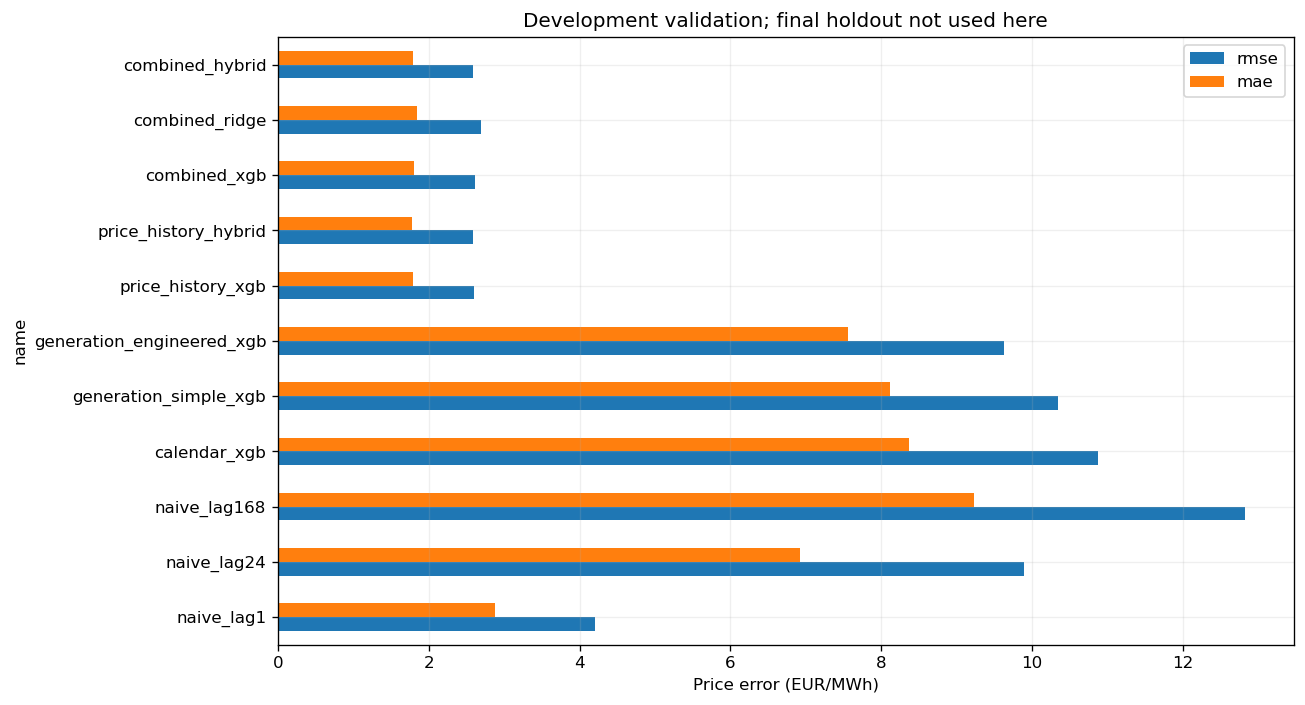

In [9]:
eligible = development[development.name.isin(experiments.index)].copy()
eligible['rmse_ratio'] = 1 - eligible['skill']
ranking = eligible.groupby(['name', 'family'], as_index=False).agg(
    mean_rmse_ratio=('rmse_ratio', 'mean'),
    worst_rmse_ratio=('rmse_ratio', 'max'),
    mean_rmse=('rmse', 'mean'),
    mean_mae=('mae', 'mean'),
).sort_values(['mean_rmse_ratio', 'name']).reset_index(drop=True)
display(ranking.round(4))

main_validation.set_index('name')[['rmse', 'mae']].plot.barh(figsize=(11, 6))
plt.title('Development validation; final holdout not used here')
plt.xlabel('Price error (EUR/MWh)')
plt.tight_layout()
plt.show()


In [10]:
selected_name = ranking.iloc[0]['name']
selected_names = [selected_name]
for family in ['generation', 'price_history', 'combined']:
    family_ranking = ranking[ranking.family == family]
    if not family_ranking.empty:
        selected_names.append(family_ranking.iloc[0]['name'])
selected_names = list(dict.fromkeys(selected_names))

final_plan = experiments.loc[selected_names].copy()
median_rounds = eligible.groupby('name')['best_round'].median()
# 与原版相同：若中位数为小数，转换为整数时向下取整。
final_plan['n_estimators'] = median_rounds.reindex(final_plan.index).apply(
    lambda value: int(value) if pd.notna(value) else None
)
final_plan['selected_overall'] = final_plan.index == selected_name
display(final_plan)


,feature_set,model_type,family,n_estimators,selected_overall
name,,,,,
price_history_hybrid,price_history,ridge+xgb,price_history,728,True
generation_engineered_xgb,generation_engineered,xgb,generation,513,False
combined_hybrid,combined,ridge+xgb,combined,502,False


## 6. 用 train + valid 重训，训练调用不接收 test

现在可以把前 85% 当作新的训练集：重新估计特征统计、填补器、标准化器和模型。
这里直接展开 `.fit`，方便和开发阶段对照：**固定 `n_estimators`，不设置 early stopping，不传 `eval_set`**。
Ridge + XGB 仍然是先 Ridge，再拟合新训练集上的残差。


In [11]:
final_features = make_feature_sets(data, validation_end)
y_train_final = y.iloc[MIN_HISTORY:validation_end].dropna()
final_models = {}

for name, spec in final_plan.iterrows():
    X_train_final = final_features[spec.feature_set].loc[y_train_final.index]
    linear, tree = None, None
    linear_prediction = np.zeros(len(y_train_final))

    if spec.model_type in ['ridge', 'ridge+xgb']:
        linear = make_pipeline(
            SimpleImputer(strategy='median', add_indicator=True),
            StandardScaler(), Ridge(alpha=RIDGE_ALPHA),
        )
        linear.fit(X_train_final, y_train_final)
        linear_prediction = linear.predict(X_train_final)

    if spec.model_type in ['xgb', 'ridge+xgb']:
        final_params = {**XGB_PARAMS, 'n_estimators': int(spec.n_estimators)}
        tree = XGBRegressor(**final_params)
        tree.fit(X_train_final, y_train_final - linear_prediction, verbose=False)

    final_models[name] = {
        'linear': linear, 'tree': tree, 'columns': list(X_train_final.columns),
    }
print('Refitted models:', list(final_models))


Refitted models: ['price_history_hybrid', 'generation_engineered_xgb', 'combined_hybrid']


## 7. 预测 test，再报告最终成绩

到这一步才读取测试标签用于评分；不根据结果重新选模型或调参数。
这是逐小时更新已观测历史后预测下一小时：测试区间后面的特征可以使用此前已发生的测试期价格。
即使下面一次调用 `.predict(X_test)`，它也不代表站在测试起点一次预测未来整个区间。


In [12]:
y_test = y.iloc[validation_end:].dropna()
naive_test = y.ffill().shift(1).loc[y_test.index]
final_rows = evaluate_baselines(y, validation_end, n)
test_predictions = {}

for name, spec in final_plan.iterrows():
    X_test = final_features[spec.feature_set].loc[y_test.index]
    prediction = predict_model(final_models[name], X_test)
    scores = evaluate(y_test, prediction, naive_test, y.iloc[:validation_end])
    test_predictions[name] = prediction
    final_rows.append(dict(
        name=name, family=spec.family, selected_overall=spec.selected_overall, **scores,
    ))

test_results = pd.DataFrame(final_rows)
display(test_results[['name', 'rmse', 'mae', 'r2', 'nrmse', 'skill', 'mase1', 'selected_overall']].round(4))
selected_test = test_results[test_results.name == selected_name].iloc[0]
print(f'Development-selected model: {selected_name}; '
      f'test RMSE={selected_test.rmse:.4f}, MAE={selected_test.mae:.4f}, '
      f'RMSE skill={selected_test.skill:.1%}')


Development-selected model: price_history_hybrid; test RMSE=1.7048, MAE=1.2304, RMSE skill=40.8%


,name,rmse,mae,r2,nrmse,skill,mase1,selected_overall
0,naive_lag1,2.8775,1.9722,0.8674,0.3641,0.0000,0.7532,NaN
1,naive_lag24,5.4112,3.9262,0.5312,0.6847,-0.8805,1.4995,NaN
2,naive_lag168,5.3809,4.0196,0.5364,0.6809,-0.8700,1.5352,NaN
3,price_history_hybrid,1.7048,1.2304,0.9535,0.2157,0.4075,0.4699,True
4,generation_engineered_xgb,12.9755,10.9196,-1.6955,1.6418,-3.5093,4.1704,False
5,combined_hybrid,1.7049,1.2287,0.9535,0.2157,0.4075,0.4693,False


## 诊断与解释

以下固定查看开发阶段选中的模型，不按照test结果改选。查看某一完整测试周只是误差展示，不用于挑选更好看的周。
同时看按小时误差、残差相关、训练期预先定义的高价区间。发现问题后可以写下一轮假设；再次开发需要新的外部留出期，不能继续把这段test称为未见数据。


High-price threshold from training: 78.118 test observations above: 649
High-price test RMSE: 1.596
Mean actual-prediction: 0.2395


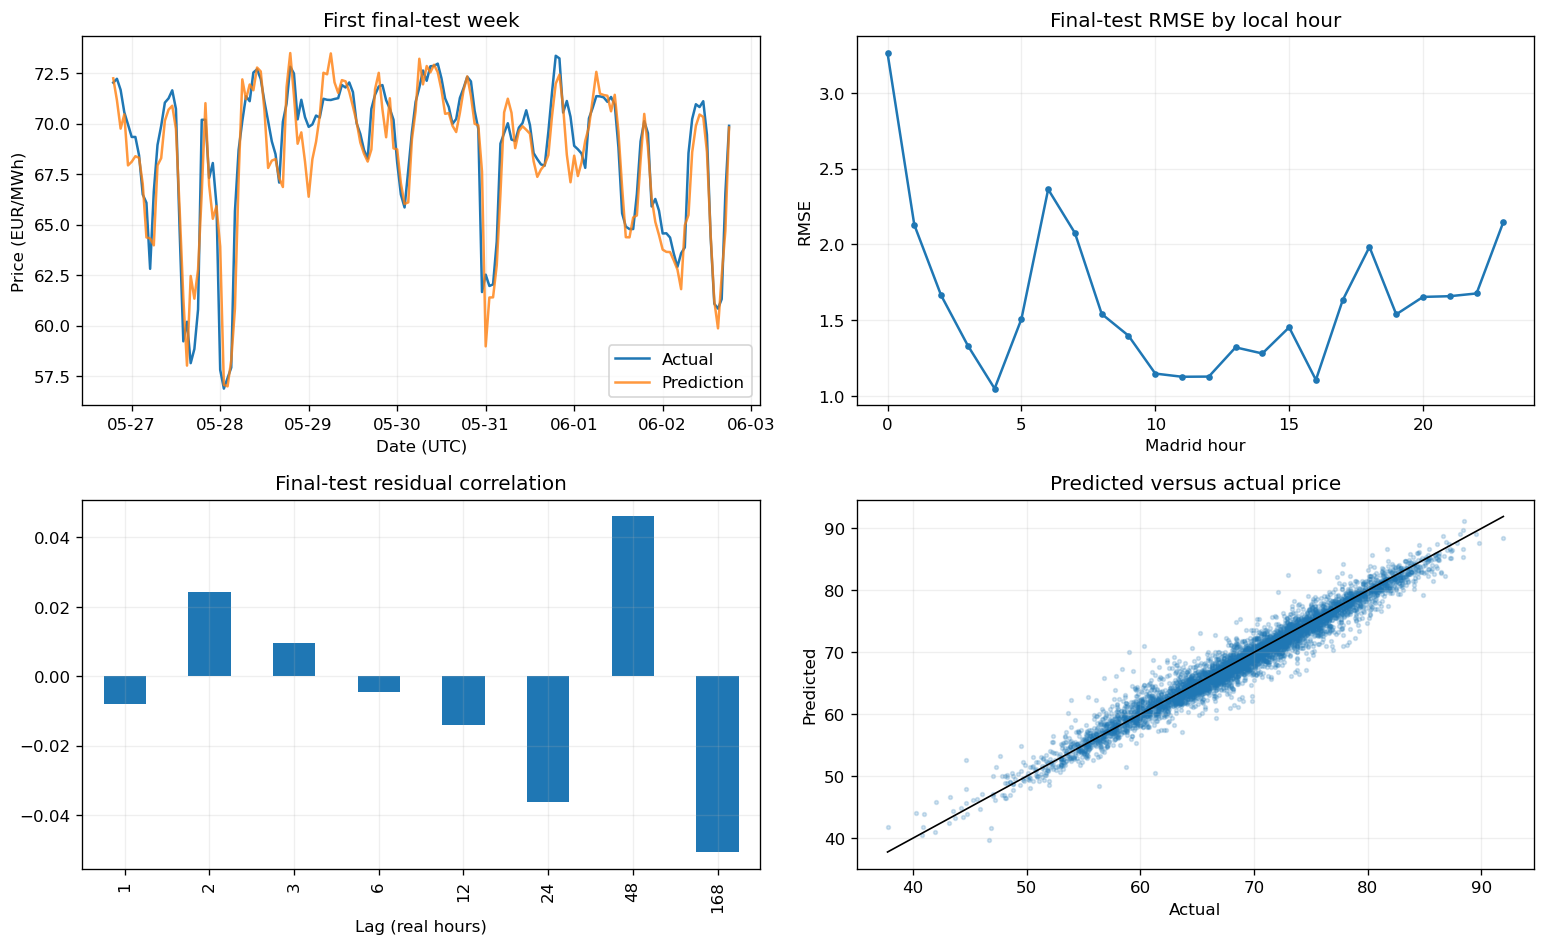

In [13]:
pred = test_predictions[selected_name]
actual = y.reindex(pred.index)
residual = actual-pred
hours = pred.index.tz_convert('Europe/Madrid').hour
fig, axes = plt.subplots(2,2,figsize=(13,8))
axes[0,0].plot(actual.iloc[:168].index,actual.iloc[:168],label='Actual')
axes[0,0].plot(pred.iloc[:168].index,pred.iloc[:168],label='Prediction',alpha=.8)
axes[0,0].set(title='First final-test week',ylabel='Price (EUR/MWh)',xlabel='Date (UTC)')
axes[0,0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
axes[0,0].legend()
residual.pow(2).groupby(hours).mean().pow(.5).plot(marker='.',ax=axes[0,1])
axes[0,1].set(title='Final-test RMSE by local hour',xlabel='Madrid hour',ylabel='RMSE')
acf = pd.Series({lag:residual.autocorr(lag) for lag in [1,2,3,6,12,24,48,168]})
acf.plot.bar(ax=axes[1,0])
axes[1,0].set(title='Final-test residual correlation',xlabel='Lag (real hours)')
axes[1,1].scatter(actual,pred,s=5,alpha=.2)
lo,hi = min(actual.min(),pred.min()),max(actual.max(),pred.max())
axes[1,1].plot([lo,hi],[lo,hi],color='black',linewidth=1)
axes[1,1].set(title='Predicted versus actual price',xlabel='Actual',ylabel='Predicted')
plt.tight_layout()
plt.show()
threshold = float(y.iloc[:validation_end].quantile(.95))
high = actual > threshold
print('High-price threshold from training:',round(threshold,3),'test observations above:',int(high.sum()))
if high.any():
    print('High-price test RMSE:',round(np.sqrt(mean_squared_error(actual[high],pred[high])),3))
print('Mean actual-prediction:',round(residual.mean(),4))


Feature importance is not causality; correlated lags can share importance.


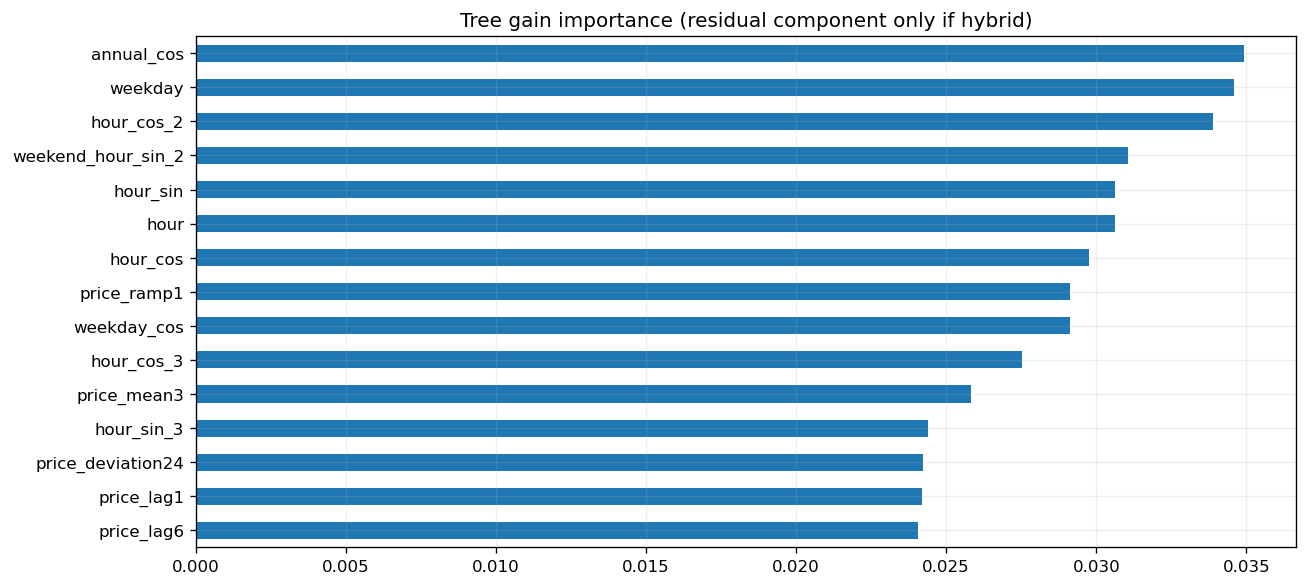

In [14]:
fitted = final_models[selected_name]
if fitted['tree'] is not None:
    importance = pd.Series(fitted['tree'].feature_importances_,index=fitted['columns']).sort_values()
    importance.tail(15).plot.barh(figsize=(11,5))
    plt.title('Tree gain importance (residual component only if hybrid)')
    plt.tight_layout()
    plt.show()
print('Feature importance is not causality; correlated lags can share importance.')


## 与上次燃气任务如何比较

不能比较“价格RMSE几个点”与“燃气RMSE几百”的大小。下面仅比较相同主验证时段、相同滚动一步协议下，各自相对lag1基线的RMSE改善。
燃气数值来自上一份已执行notebook的实验记录，未在本notebook重训；价格使用本次开发阶段选定模型在主验证段的成绩。它们均为开发结果，不是两个任务的独立难度证明。

各family的优胜者可能使用不同算法。判断发电量的增量，应在主验证表中匹配比较`price_history_xgb`与`combined_xgb`，以及`price_history_hybrid`与`combined_hybrid`，而不是把不同算法的差异全部归因于特征。


In [15]:
gas_naive_rmse = 653.6739816870493
gas_eda_hybrid_rmse = 371.802642715658
price_dev = main_validation[main_validation.name==selected_name].iloc[0]
price_naive = main_validation[main_validation.name=='naive_lag1'].iloc[0]
comparison = pd.DataFrame([
    {'task':'Previous gas (EDA Ridge+XGB)','model_rmse':gas_eda_hybrid_rmse,
     'naive1_rmse':gas_naive_rmse,'rmse_skill':1-gas_eda_hybrid_rmse/gas_naive_rmse},
    {'task':'Price ('+selected_name+')','model_rmse':price_dev.rmse,
     'naive1_rmse':price_naive.rmse,'rmse_skill':price_dev.skill},
])
print('Same main validation period; raw RMSE units differ:\n',comparison.round(4).to_string(index=False))
print('\nFamily-selected pipelines on main validation (algorithms may differ):')
for family in ['generation','price_history','combined']:
    family_ranking = ranking[ranking.family == family]
    if family_ranking.empty:
        continue
    name = family_ranking.iloc[0]['name']
    result = main_validation[main_validation.name==name].iloc[0]
    print(f'{family:15} {name:27} RMSE={result.rmse:.3f}, skill={result.skill:.1%}')


Same main validation period; raw RMSE units differ:
                         task  model_rmse  naive1_rmse  rmse_skill
Previous gas (EDA Ridge+XGB)    371.8026      653.674      0.4312
Price (price_history_hybrid)      2.5913        4.199      0.3829

Family-selected pipelines on main validation (algorithms may differ):
generation      generation_engineered_xgb   RMSE=9.625, skill=-129.2%
price_history   price_history_hybrid        RMSE=2.591, skill=38.3%
combined        combined_hybrid             RMSE=2.591, skill=38.3%


## 迁移到其他预测问题：先复制这段最小流程

下面是上面开发循环中“一次训练”的等价写法。使用前面的函数和参数，不必同时运行八组实验。
`feature_set` 可换成已有五套特征中的任意一套；模型类型可选 `xgb`、`ridge`、`ridge+xgb`。

```python
features = make_feature_sets(data, fit_end=train_end)
X = features['combined']
X_train, X_valid, y_train, y_valid = split_xy(
    X, y, train_end, validation_end, MIN_HISTORY,
)
model = fit_with_validation(
    X_train, y_train, X_valid, y_valid,
    model_type='xgb', xgb_params=XGB_PARAMS,
    patience=EARLY_STOPPING_ROUNDS, ridge_alpha=RIDGE_ALPHA,
)
prediction = predict_model(model, X_valid)
scores = evaluate(
    y_valid, prediction, y.ffill().shift(1).loc[y_valid.index], y.iloc[:train_end],
)
```

| 迁移时要调整 | 原因 |
|---|---|
| 数据源、目标、预测跨度及信息可用时间 | 先明确预测时到底已知什么；24小时提前预测不能直接沿用本例的 lag1 |
| `make_feature_sets`、`MIN_HISTORY` | 当前特征含电力字段、Madrid时区和最长169小时lag；不能只改 TARGET 就用于别的数据 |
| 时间边界、`FOLDS` | 当前比例仅适用于本次练习；其他任务要覆盖实际季节和部署跨度 |
| 基线、指标、模型参数 | lag1与MASE1假设小时一步预测；其他频率或目标应重新定义 |

训练骨架可复用：**先切分 → 只在训练段 fit → 验证选方案 → 固定参数重训 → test 评价**。
换成分类等任务时也要更换 estimator 和评分函数。附录中的燃气任务比较是本数据专用分析，无需复制。


## 下一步学习：先提出问题，再增加复杂度

- 比较只有raw calendar与Fourier/one-hot/spline；XGB并不强制sin/cos。注意工作日与日内周期的交互。
- 比较预测价格水平与预测price_t−price_(t−1)或price_t−price_(t−24)，预测差分后必须加回，并在原始价格尺度评分。
- 按源分组移除发电特征，衡量其对历史价格模型的额外价值；不要仅按gain逐列删除高度相关特征。
- 比较expanding与近期sliding窗口，检查年份之间机制变化。当前固定参数不是最优参数搜索结果。
- 真正提前24小时预测时，需要重写可用信息集合；不能在第2小时使用尚未知晓的第1小时真实价格或发电量。
- forecast列与日前价只有在历史发布时间/版本明确后才加入。若某价格本来已提前公布，一小时预测成绩不代表可交易价值。
- 不使用全样本去季节化、centered rolling、未来插值或当天尚未结束的日总量。缺失值、量纲、发布延迟都属于特征定义的一部分。

参考：
- [同一数据集的Lightning电价预测教程](https://lightning-flash.readthedocs.io/en/stable/notebooks/flash_tutorials/electricity_forecasting.html)：同样以price actual做自回归学习；这里使用XGBoost/Ridge。
- [原始Kaggle数据集](https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather)：原始数据来源；本次未取得可读的完整价格产品说明。
- [scikit-learn周期特征工程](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html)：比较时间编码与模型表达能力。
- [XGBoost sklearn接口](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html)：early stopping与预测行为。
- [OMIE市场规则（2018）](https://www.omie.es/sites/default/files/2019-12/market_rules_2018_0.pdf)：日前市场涉及次日小时产品，不能仅凭CSV时间戳推断价格当时未知。
